In [1]:
using Pkg
Pkg.activate("path/to/project")
using MajoranaPropagation
using Revise
using PauliPropagation
using Plots

  Activating project at `c:\Users\jugro\Desktop\8Sem_ETH\Research Project\Simulations\path\to\project`


In [5]:
n_fermions = 8
mstring = MajoranaString(n_fermions, [1, 2])

n3 = MajoranaSum(n_fermions, :n, 3) #sum of MajoranaStrings, not sum of gammas ->imaginary unit is not needed
n4 = MajoranaSum(n_fermions, :n, 4) 


@show n3 * n4 #Multiplication
@show add!(n3,n4) #Addition, or write add!(n3, :n, 4)



n3 * n4 = MajoranaSum with 4 terms:
    0.25 * 0000000000000000
    -0.25 * 0000111100000000
    0.25 * 0000001100000000
    0.25 * 0000110000000000
add!(n3, n4) = MajoranaSum with 3 terms:
    1.0 * 0000000000000000
    0.5 * 0000001100000000
    0.5 * 0000110000000000


MajoranaSum with 3 terms:
    1.0 * 0000000000000000
    0.5 * 0000001100000000
    0.5 * 0000110000000000

In [ ]:
n_fermions = 7
majorana_rotation = MajoranaRotation(MajoranaString(n_fermions, [5, 6])) # create the Majorana rotation corresponding to the non-trivial part of n_3
@show majorana_rotation

fermionic_gate = FermionicGate(:n, 3)#Unitary gate corresponding to time evolution
@show fermionic_gate

#we can check that they are equivalent
majorana_rotations, _ = MajoranaPropagation.getmajoranarotations(fermionic_gate, n_fermions) #_ a placeholder?
@show majorana_rotations;

majorana_rotation = MajoranaRotation{UInt16}(0x0030)
fermionic_gate = FermionicGate(:n, [3])
majorana_rotations = MajoranaRotation{UInt16}[MajoranaRotation{UInt16}(0x0030)]


In [ ]:
obs = MajoranaSum(n_fermions, :hop, [1 ,3]) #observable we are interested in

propagate!([fermionic_gate], obs, [0.2]) #propagate the observable for a time step of 0.2 in the Heisenberg picture

MajoranaSum with 4 terms:
    0.09933466539753061 * 0100010000000000
    0.4900332889206208 * 1000010000000000
    -0.4900332889206208 * 0100100000000000
    0.09933466539753061 * 1000100000000000

In [ ]:
n_sites = 2 
gate = FermionicGate(:hop, [1, 2])
o1 = MajoranaSum(n_sites, :n, 1)
add!(o1, :n, 2) #like +=
propagate!([gate], o1, [0.1]; min_abs_coeff=1.e-10, truncate_each_mr=true)#truncation at 0.01

#define again the same observable 
o2 = MajoranaSum(n_sites, :n, 1)
add!(o2, :n, 2)
propagate!([gate], o2, [0.1]; min_abs_coeff=0.1, truncate_each_mr=true)#truncation at 0.1, 
#truncate_each_mr=true ->truncation after each Majorana rotation
#truncate_each_mr=false ->truncation only after the fermionic gate


@show o1 
@show o2;#not conserving oventhough gate is number conserving


o1 = MajoranaSum with 3 terms:
    1.0 * 00000000
    0.5 * 00110000
    0.5 * 11000000
o2 = MajoranaSum with 3 terms:
    1.0 * 00000000
    0.49501664446031046 * 00110000
    0.49501664446031046 * 11000000


In [ ]:
#dont understand default truncation method:
#In order to avoid this, the current default option in the code is to truncate after the fermionic gate for 
#gates that are potentially non-number conserving even if they should (like hopping terms), and to truncate after 
#each Majorana rotation if the individual Majorana strings are number preserving (like repulsion terms).

In [58]:
using Revise
using MajoranaPropagation
using PauliPropagation
using Plots 

n_sites = 2 
gate = FermionicGate(:hop, [1, 2])
o1 = MajoranaSum(n_sites, :n, 1)
add!(o1, :n, 2) #or: add!(o1, MajoranaSum(n_sites, :n, 2))
propagate!([gate], o1, [0.1]; min_abs_coeff=1.e-10, truncate_each_mr=true)

#define again the same observable 
o2 = MajoranaSum(n_sites, :n, 1)
add!(o2, :n, 2)
propagate!([gate], o2, [0.1]; min_abs_coeff=0.01, truncate_each_mr=true)

#i have no idea whats the difference here, sure we have different coeff truncation conditions
@show o1 
@show o2;


o1 = MajoranaSum with 3 terms:
    1.0 * 00000000
    0.5 * 00110000
    0.5 * 11000000
o2 = MajoranaSum with 3 terms:
    1.0 * 00000000
    0.5 * 00110000
    0.5 * 11000000


In [59]:
n_sites = 2 
gate = FermionicGate(:hop, [1, 2])
o1 = MajoranaSum(n_sites, :n, 1)
add!(o1, :n, 2)
propagate!([gate], o1, [0.1]; min_abs_coeff=1.e-10, truncate_each_mr=true)

#define again the same observable 
o2 = MajoranaSum(n_sites, :n, 1)
add!(o2, :n, 2)
propagate!([gate], o2, [0.1]; min_abs_coeff=0.1, truncate_each_mr=true)

@show o1 
@show o2;

o1 = MajoranaSum with 3 terms:
    1.0 * 00000000
    0.5 * 00110000
    0.5 * 11000000
o2 = MajoranaSum with 3 terms:
    1.0 * 00000000
    0.49501664446031046 * 00110000
    0.49501664446031046 * 11000000


In [67]:
n_sites = 20 
topo = bricklayertopology(n_sites; periodic=true) #1D chain with periodic boundary conditions

obs = MajoranaSum(n_sites, :nn, [4, 8])#Operator expansion in majorana strings 

gates = []
thetas = []
dt = 0.05
h = 1.
J = 0.5

for pair in topo 
    push!(gates, FermionicGate(:hop, pair))
    push!(thetas, 0.1)
end

for pair in topo 
    push!(gates, FermionicGate(:nn, pair))
    push!(thetas, 0.05)
end

initial_state = FockState(n_sites, 1:2:n_sites) #Fock state with 10 fermions at positions: 1, 3, 5, 7, 9, 11, 13, 15, 17, 19

#simulation
min_abs_coeff = 1.e-4
n_layers = 55 

obs_default = deepcopy(obs)
obs_true = deepcopy(obs)
obs_false = deepcopy(obs)

res_default = zeros(n_layers+1)
res_true = zeros(n_layers+1)
res_false = zeros(n_layers+1)

lengths_default = zeros(n_layers+1)
lengths_true = zeros(n_layers+1)
lengths_false = zeros(n_layers+1)

res_default[1] = overlapwithfock(obs_default, initial_state)
res_true[1] = overlapwithfock(obs_true, initial_state)
res_false[1] = overlapwithfock(obs_false, initial_state)
lengths_default[1] = length(obs_default)
lengths_true[1] = length(obs_true)
lengths_false[1] = length(obs_false)

total_time_default = 0.0
total_time_true = 0.0
total_time_false = 0.0


for j = 1:n_layers 
    print("$j ")
    time_default = @elapsed propagate!(gates, obs_default, thetas; min_abs_coeff=min_abs_coeff)
    # truncate after each Majorana rotation 
    time_true = @elapsed propagate!(gates, obs_true, thetas; min_abs_coeff=min_abs_coeff, truncate_each_mr=true)
    # truncate only after the full fermionic gate
    time_false = @elapsed propagate!(gates, obs_false, thetas; min_abs_coeff=min_abs_coeff, truncate_each_mr=false)

    res_default[j+1] = overlapwithfock(obs_default, initial_state)
    res_true[j+1] = overlapwithfock(obs_true, initial_state)
    res_false[j+1] = overlapwithfock(obs_false, initial_state)

    lengths_default[j+1] = length(obs_default)
    lengths_true[j+1] = length(obs_true)
    lengths_false[j+1] = length(obs_false)

    total_time_default += time_default
    total_time_true += time_true
    total_time_false += time_false
end
println()

println("Total time default: $total_time_default")
println("Total time true: $total_time_true")
println("Total time false: $total_time_false");

1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 54 55 
Total time default: 35.0826467
Total time true: 32.348209499999996
Total time false: 36.14405240000001


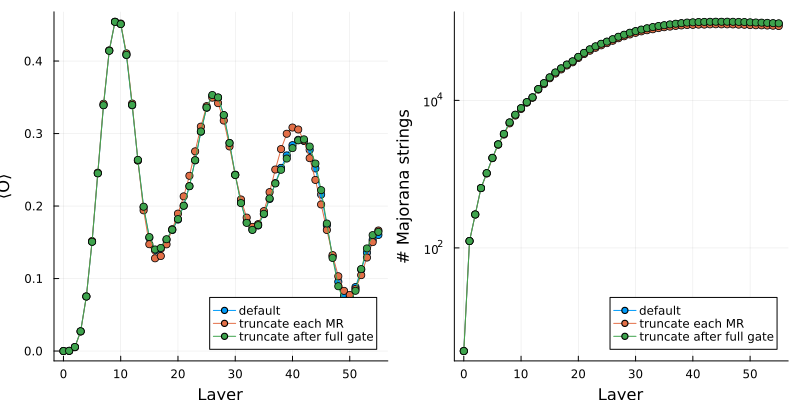

In [68]:
ev_plot = plot(xlabel="Layer", ylabel="⟨O⟩", legend=:bottomright)
plot!(ev_plot, 0:n_layers, res_default, label="default", marker=:circle)
plot!(ev_plot, 0:n_layers, res_true, label="truncate each MR", marker=:circle)
plot!(ev_plot, 0:n_layers, res_false, label="truncate after full gate", marker=:circle)

length_plot = plot(xlabel="Layer", ylabel="# Majorana strings", yscale=:log10, legend=:bottomright)
plot!(length_plot, 0:n_layers, lengths_default, label="default", marker=:circle)
plot!(length_plot, 0:n_layers, lengths_true, label="truncate each MR", marker=:circle)
plot!(length_plot, 0:n_layers, lengths_false, label="truncate after full gate", marker=:circle)

plot(ev_plot, length_plot, layout=(1,2), size=(800,400))

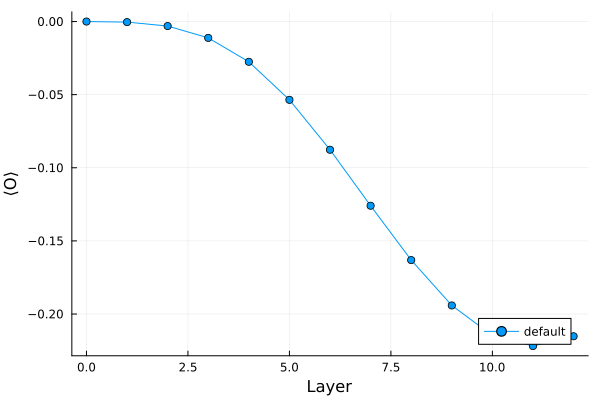

In [7]:
using Plots
function MajoranaPropagation.MajoranaSum(n_sites::Integer, ::Val{:nn_par_hol_symmetric}, sites)
    site1 = minimum(sites)
    site2 = maximum(sites)
    is_spinful = false
    obs = MajoranaSum(n_sites, [2*site1-1, 2*site1, 2*site2-1, 2*site2], is_spinful; coeff=-0.5)  #γiγi'γjγj' due to n->2n indexing
    #get correct inttype
    TT = PauliPropagation.getinttype(nfermions(obs))
    add!(obs, TT(0), 0.5)   #identity operator added to the MajoranaSum
    return obs
end

#with this, we can seupt a fermionic gate:
n_sites = 15
topo = bricklayertopology(n_sites; periodic=true)

gates = []
thetas = []
dt = 0.05
h = 1.
J = 0.5

for pair in topo 
    push!(gates, FermionicGate(:hop, pair))
    push!(thetas, 0.1)
end

for pair in topo 
    push!(gates, FermionicGate(:nn_par_hol_symmetric, pair))
    push!(thetas, 0.05)
end
     
n_layers = 12
min_abs_coeff = 1.e-5
initial_state = FockState(n_sites, 1:2:n_sites)

obs = MajoranaSum(n_sites, :hop, [1, 4])
res=zeros(n_layers+1)
res[1]=overlapwithfock(obs, initial_state)

for j=1:n_layers
    propagate!(gates, obs, thetas; min_abs_coeff=min_abs_coeff)
    res[j+1] = overlapwithfock(obs, initial_state)
end

ev_plot = plot(xlabel="Layer", ylabel="⟨O⟩", legend=:bottomright)
plot!(ev_plot, 0:n_layers, res, label="default", marker=:circle)
plot(ev_plot, size=(800,400))
display(ev_plot)

#Overwrite the by default trucation after each Majorana rotation
function MajoranaPropagation.flag_non_number_preserving(::Val{:nn_par_hol_symmetric})
    return true
end

1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 

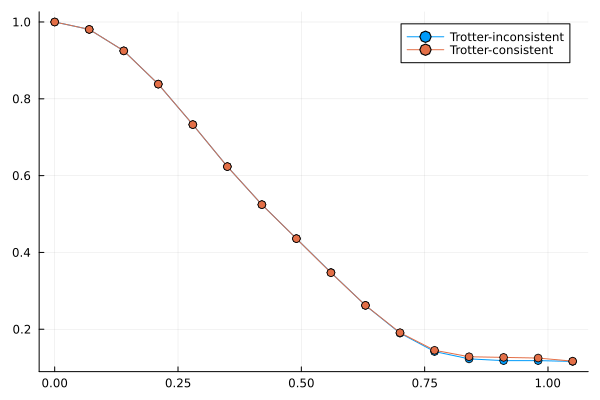

In [ ]:
using Base.Threads
using Plots

N_x = 5
N_y = 5
N_spinful_sites = N_x * N_y
t = 1.
U = 8.

n_layers = 15
dt = 0.07;

min_abs_coeff = 5.e-
max_unpaired = 4
max_unpaired_in_step = 6
unpaired_mask = create_unpaired_mask(2 * N_spinful_sites);

topo = rectangletopology(N_x, N_y)

circ_single = []
thetas_single = []

#up hoppings 
for (i, j) in topo
    push!(circ_single, FermionicGate(:hopup, [i, j]))
    push!(thetas_single, -t * dt)
end

#down hoppings 
for (i, j) in topo
    push!(circ_single, FermionicGate(:hopdn, [i, j]))
    push!(thetas_single, -t * dt)
end

#on-site repulsion 
for i = 1:N_spinful_sites
    push!(circ_single, FermionicGate(:nupndn, i))
    push!(thetas_single, U * dt)
end

#initial state 
initial_state_label = "Hole checkerboard"
is_spinful = true
hole_pos = 13
fock_state = FockState(N_spinful_sites, :checkerboard, is_spinful; nx=N_x, hole_positions=hole_pos)

obs = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :hole, hole_pos))
obs_trotter_consistent = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :hole, hole_pos))

res = zeros(n_layers+1)
res_trotter_consistent = zeros(n_layers+1)

res[1] = overlapwithfock(obs, fock_state)
res_trotter_consistent[1] = overlapwithfock(obs_trotter_consistent, fock_state)

for k=1:n_layers
    print(k, " ")
    obs = propagate!(circ_single, obs, thetas_single, min_abs_coeff=min_abs_coeff, max_unpaired=max_unpaired, unpaired_mask=unpaired_mask)
    obs_trotter_consistent = propagate!(circ_single, obs_trotter_consistent, thetas_single, min_abs_coeff=min_abs_coeff, max_unpaired=max_unpaired_in_step, unpaired_mask=unpaired_mask)

    obs_trotter_consistent = truncate!(obs_trotter_consistent, min_abs_coeff=-1, max_unpaired=max_unpaired, unpaired_mask=unpaired_mask)

    res[k+1] = overlapwithfock(obs, fock_state)
    res_trotter_consistent[k+1] = overlapwithfock(obs_trotter_consistent, fock_state)
end 

p = plot((0:n_layers) .* dt, res, label="Trotter-inconsistent", marker=:o)
plot!((0:n_layers) .* dt, res_trotter_consistent, label="Trotter-consistent", marker=:o)
     



In [9]:
# Set parameters
L_sites = 10
t_hop = 1.0
U_repulsion = 2.0
dt = 0.1
n_steps = 6

# Create Hamiltonian
topo = bricklayertopology(L_sites)

circ_single_step = []
thetas_single_step = []
for (i, j) in topo
    push!(circ_single_step, FermionicGate(:hop, [i, j]))
    push!(thetas_single_step, -t_hop * dt)
end
for (i, j) in topo
    push!(circ_single_step, FermionicGate(:nn, [i, j]))
    push!(thetas_single_step, U_repulsion * dt)
end


# Set initial Fock state
# specify the sites where fermions are created
fock_state = FockState(L_sites, 1:2:L_sites)

# Set observable 
obs = MajoranaSum(L_sites, :n, 1) * MajoranaSum(L_sites, :n, 5)
@show obs 

# Propagate 
for step = 1:n_steps
    propagate!(circ_single_step, obs, thetas_single_step; min_abs_coeff=1.e-8)
    @show overlapwithfock(obs, fock_state)
end
# Consider a second Fock state that only differs by the position of one fermion
fock_state = FockState(L_sites, 1:2:L_sites)

sites2 = collect(1:2:L_sites)
sites2[1] = 2
fock_state_2 = FockState(L_sites, sites2)

# Set observable 
obs = MajoranaSum(L_sites, :n, 1) * MajoranaSum(L_sites, :n, 5)

# Propagate
for step = 1:n_steps
    propagate!(circ_single_step, obs, thetas_single_step; min_abs_coeff=1.e-8)
    o1 = overlapwithfock(obs, fock_state)
    o2 = overlapwithfock(obs, fock_state_2)

    # compute the overlap with the equal superposition of the two Fock states
    osuper = overlapwithfock(obs, [fock_state, fock_state_2], [1 / sqrt(2), 1 / sqrt(2)])
    @show osuper
end

obs = MajoranaSum with 4 terms:
    0.25 * 000000000000000000000000
    0.25 * 000000001100000000000000
    0.25 * 110000000000000000000000
    -0.25 * 110000001100000000000000
overlapwithfock(obs, fock_state) = 0.9704952279877588
overlapwithfock(obs, fock_state) = 0.8882124807595978
overlapwithfock(obs, fock_state) = 0.7699323188470679
overlapwithfock(obs, fock_state) = 0.6373690993931244
overlapwithfock(obs, fock_state) = 0.5104984654742456
overlapwithfock(obs, fock_state) = 0.4027495776515425
osuper = 0.49013262425036064
osuper = 0.46211972377843524
osuper = 0.4204815067033148
osuper = 0.371618191156206
osuper = 0.32237122015294195
osuper = 0.2787254260226416
